# Normalisation de Texte Informel (Langage / Chat)
**Étudiant :** Youssef Nafae  |  **Pipeline :** BPE → Seq2Seq (GRU + attention) → BLEU → export → Streamlit / 


## Section 1 — Introduction du projet
**Problème.** Les messages Twitter/chat contiennent des abréviations (`thx`), des mots allongés (`thaaaaaaaaank`), des fautes et des symboles. Ils sont difficiles à traiter pour la plupart des outils de NLP.

**Objectif.** Construire un système qui transforme un message informel en anglais normalisé en conservant le sens, en apprenant à partir du corpus parallèle fourni (aucun dictionnaire manuel d'abréviations).

**Architecture.**
1. *Prétraitement minimal* (espaces, Unicode) sans perte d'information.
2. *Tokenisation BPE* (entraînée uniquement sur le train) : découpe en sous-mots pour gérer les mots inconnus. BPE ne normalise pas : c'est seulement une représentation.
3. *Seq2Seq contextuel au niveau du mot* : chaque mot bruité, avec ses 2 voisins de chaque côté, est traduit en son mot normalisé (encodeur GRU bidirectionnel, attention additive, décodeur GRU).
4. *Décodage glouton*, évaluation **BLEU (SacreBLEU)** sur le test, analyse d'erreurs.
5. *Export* des artefacts et démo **Streamlit** déployable sur Hugging Face Spaces.

**Sorties attendues :** modèle entraîné, tokenizer BPE, score BLEU sur le test, analyse d'erreurs, `normalize_text(text)`, archive ZIP, `app.py`.

## Section 2 — Environnement et reproductibilité
On vérifie le GPU, on importe uniquement les bibliothèques nécessaires, on fixe les graines et on centralise **tous les chemins** dans une seule cellule.

In [1]:
import os, re, json, time, random, unicodedata, shutil, subprocess, sys
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# ---- Chemins configurables ----
INPUT_ROOT   = Path("/kaggle/input")
WORKING_DIR  = Path("/kaggle/working")
ARTIFACT_DIR = WORKING_DIR / "normalizer_model"     # modèle + tokenizer + code d'inférence
SPACE_DIR    = WORKING_DIR / "hf_space"             # app Streamlit prête pour Hugging Face
# Si la détection automatique des fichiers échoue, renseigne ici les chemins à la main :
MANUAL_PATHS = {}   # ex. {"train": "/kaggle/input/mon-dataset/train.txt", "dev": "...", "test": "..."}

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True); SPACE_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
else: print("Pas de GPU : active un accélérateur dans Kaggle (Settings > Accelerator) pour accélérer l'entraînement.")

PyTorch: 2.11.0+cu128 | device: cuda
GPU: Tesla T4


## Section 3 — Découverte et chargement des données
**3.1** On liste tout ce qui se trouve dans `/kaggle/input/`.

In [2]:
assert INPUT_ROOT.exists(), f"{INPUT_ROOT} introuvable : ajoute ton dataset au notebook (Add Input)."
all_files = sorted(p for p in INPUT_ROOT.rglob("*") if p.is_file())
for p in all_files:
    print(f"{p}  ({p.stat().st_size/1024:.1f} Ko)")
assert all_files, "Aucun fichier dans /kaggle/input : le dataset privé n'est pas attaché au notebook."

/kaggle/input/datasets/nafaeyoussef/multilexnorm/dev.norm  (102.9 Ko)
/kaggle/input/datasets/nafaeyoussef/multilexnorm/test.norm  (328.8 Ko)
/kaggle/input/datasets/nafaeyoussef/multilexnorm/train.norm  (393.9 Ko)


**3.2** On identifie les fichiers train / dev / test d'après leurs noms. Si un split correspond à 0 ou à plusieurs fichiers, on **s'arrête** (ou on utilise `MANUAL_PATHS`). On affiche ensuite les premières lignes brutes (`repr`) pour voir les tabulations et lignes vides.

In [3]:
SPLIT_PATTERNS = {
    "train": r"(^|[^a-z])train",
    "dev":   r"(^|[^a-z])(dev|valid|validation|val)([^a-z]|$)",
    "test":  r"(^|[^a-z])test",
}
def find_split_files():
    if MANUAL_PATHS:
        paths = {k: Path(v) for k, v in MANUAL_PATHS.items()}
        assert set(paths) == {"train", "dev", "test"}, "MANUAL_PATHS doit contenir train, dev et test."
        for k, p in paths.items(): assert p.is_file(), f"Fichier introuvable pour {k}: {p}"
        return paths
    candidates = [p for p in all_files if "readme" not in p.name.lower() and p.suffix.lower() not in {".md", ".json", ".pdf", ".zip"}]
    found = {}
    for split, pattern in SPLIT_PATTERNS.items():
        matches = [p for p in candidates if re.search(pattern, str(p.relative_to(INPUT_ROOT)).lower())]
        if len(matches) != 1:
            raise ValueError(f"Split '{split}': {len(matches)} fichier(s) correspondant(s) {[str(m) for m in matches]}. "
                             "Renseigne MANUAL_PATHS dans la Section 2.")
        found[split] = matches[0]
    if len(set(found.values())) != 3:
        raise ValueError(f"Un même fichier est associé à plusieurs splits : {found}. Renseigne MANUAL_PATHS.")
    return found

split_files = find_split_files()
for split, path in split_files.items():
    print(f"\n=== {split.upper()} : {path} ===")
    with open(path, encoding="utf-8", errors="replace") as f:
        for _ in range(14): print(repr(f.readline()))


=== TRAIN : /kaggle/input/datasets/nafaeyoussef/multilexnorm/train.norm ===
'rt\trt\n'
'@teddyferrari1\t@teddyferrari1\n'
':\t:\n'
'"\t"\n'
'ah\tah\n'
'...\t...\n'
'@datzmenoni\t@datzmenoni\n'
':\t:\n'
'why\twhy\n'
'sub\tsub\n'
'ozil\tozil\n'
'"\t"\n'
'@lexzydoo_ab\t@lexzydoo_ab\n'
':\t:\n'

=== DEV : /kaggle/input/datasets/nafaeyoussef/multilexnorm/dev.norm ===
'@cdutra5\t@cdutra5\n'
'bruh\tbrother\n'
'get\tget\n'
'out\tout\n'
'yo\tyour\n'
'feelings\tfeelings\n'
'lol\tlol\n'
'\n'
'rt\trt\n'
'@demberel_s\t@demberel_s\n'
':\t:\n'
'manan\tmanan\n'
'dund\tdund\n'
'xaragdax\txaragdax\n'

=== TEST : /kaggle/input/datasets/nafaeyoussef/multilexnorm/test.norm ===
'@ez_doesssit\t@ez_doesssit\n'
'yeh\tyeah\n'
'but\tbut\n'
'still\tstill\n'
"that's\tthat's\n"
'wild\twild\n'
'lol\tlol\n'
'\n'
'dick\tdick\n'
'in\tin\n'
'janice\tjanice\n'
',\t,\n'
"im\ti'm\n"
'poppin\tpopping\n'


**3.3** Parseur adaptatif. Trois formats sont reconnus automatiquement :
- `alternating_lines` : une ligne = un token informel, la ligne suivante = son token normalisé, lignes vides entre les messages ;
- `tab_tokens` : `informel<TAB>normalisé` par ligne, lignes vides entre les messages ;
- `tab_sentences` : un message par ligne `source<TAB>cible`.

Les blocs malformés (nombre impair de lignes, colonnes manquantes) sont **comptés et ignorés**, jamais devinés. Un autre format provoque une erreur explicite.

In [4]:
def read_lines(path):
    with open(path, encoding="utf-8", errors="replace") as f:     # errors="replace": pas de crash sur un octet invalide
        return [line.rstrip("\r\n") for line in f]

def detect_format(lines, path):
    non_blank = [l for l in lines if l.strip()]
    assert non_blank, f"{path} est vide."
    n_blank = len(lines) - len(non_blank)
    tab_ratio = np.mean(["\t" in l for l in non_blank])
    if tab_ratio > 0.9:
        cell_words = [len(c.split()) for l in non_blank[:2000] for c in l.split("\t")]
        return "tab_tokens" if (n_blank > 0 and np.median(cell_words) == 1) else "tab_sentences"
    words_per_line = np.mean([len(l.split()) for l in non_blank[:5000]])
    if n_blank > 0 and tab_ratio == 0 and words_per_line < 1.5:
        return "alternating_lines"
    raise ValueError(f"Format non reconnu pour {path} (tab_ratio={tab_ratio:.2f}, lignes vides={n_blank}, "
                     f"mots/ligne={words_per_line:.2f}). Adapte parse_file() à ce format.")

def parse_file(path):
    lines = read_lines(path)
    fmt = detect_format(lines, path)
    messages, n_malformed = [], 0
    if fmt == "tab_sentences":
        for i, line in enumerate(lines):
            if i == 0 and line.split("\t")[0].strip().lower() in {"source", "src", "informal", "noisy", "input", "text"}:
                continue                                              # ligne d'en-tête
            parts = line.split("\t")
            if len(parts) != 2 or not parts[0].strip() or not parts[1].strip():
                n_malformed += bool(line.strip()); continue
            messages.append((parts[0].split(), parts[1].split()))
    else:
        blocks, current = [], []
        for line in lines + [""]:
            if line.strip() == "":
                if current: blocks.append(current); current = []
            else: current.append(line.strip())
        for block in blocks:
            if fmt == "tab_tokens":
                cols = [l.split("\t") for l in block]
                if any(len(c) != 2 for c in cols): n_malformed += 1; continue
                src_tokens, tgt_tokens = [c[0].strip() for c in cols], [c[1].strip() for c in cols]
            else:
                if len(block) % 2 != 0: n_malformed += 1; continue    # nombre impair => alignement impossible
                src_tokens, tgt_tokens = block[0::2], block[1::2]
            messages.append((src_tokens, tgt_tokens))
    df = pd.DataFrame({
        "src_tokens": [m[0] for m in messages], "tgt_tokens": [m[1] for m in messages]})
    df["source_text"] = df.src_tokens.map(lambda t: " ".join(" ".join(t).split()))
    df["target_text"] = df.tgt_tokens.map(lambda t: " ".join(" ".join(t).split()))
    return df, fmt, n_malformed

raw = {}
for split, path in split_files.items():
    df, fmt, n_bad = parse_file(path)
    assert len(df) > 0, f"Aucun message lu dans {path}."
    raw[split] = df
    print(f"{split:5s} | format={fmt:17s} | messages={len(df):6d} | blocs malformés ignorés={n_bad}")
train_df, dev_df, test_df = raw["train"].copy(), raw["dev"].copy(), raw["test"].copy()

train | format=tab_tokens        | messages=  2351 | blocs malformés ignorés=9
dev   | format=tab_tokens        | messages=   589 | blocs malformés ignorés=1
test  | format=tab_tokens        | messages=  1954 | blocs malformés ignorés=13


**3.3b** Deux choix de données (à citer dans le rapport) : (1) filtre de langue optionnel, qui retire du **train** les messages dont les mots normalisés sont peu anglais (dictionnaire NLTK) ; (2) remplacement de toutes les mentions `@nom` par `[user]` dans la source **et** la cible. Les vraies mentions sont remises à l'inférence.

In [5]:
ENGLISH_FILTER, MIN_ENGLISH_RATIO, FILTER_DEV_TEST = True, 0.5, False   # mets ta valeur de seuil habituelle
try:
    from nltk.corpus import words as nltk_words
    english_vocab = {w.lower() for w in nltk_words.words()}
except LookupError:
    import nltk; nltk.download("words")                                  # nécessite Internet activé
    from nltk.corpus import words as nltk_words
    english_vocab = {w.lower() for w in nltk_words.words()}

def english_ratio(tgt_tokens):
    words = []
    for t in tgt_tokens:
        for w in t.lower().split():                                       # une cible peut contenir plusieurs mots
            base = w.split("'")[0]
            if base.isalpha() and w != "rt": words.append((w, base))
    if not words: return 1.0
    return sum((w in english_vocab) or (b in english_vocab) for w, b in words) / len(words)

if ENGLISH_FILTER:
    for name, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
        print(f"{name}: {(df.tgt_tokens.map(english_ratio) < MIN_ENGLISH_RATIO).sum()} messages sous le seuil")
    keep = lambda df: df[df.tgt_tokens.map(english_ratio) >= MIN_ENGLISH_RATIO].reset_index(drop=True)
    train_df = keep(train_df)
    if FILTER_DEV_TEST: dev_df, test_df = keep(dev_df), keep(test_df)

def mask_token(t): return "[user]" if t.startswith("@") else t
for df in (train_df, dev_df, test_df):
    df["src_tokens"] = df.src_tokens.map(lambda ts: [mask_token(t) for t in ts])
    df["tgt_tokens"] = df.tgt_tokens.map(lambda ts: [mask_token(t) for t in ts])
    df["source_text"] = df.src_tokens.map(" ".join); df["target_text"] = df.tgt_tokens.map(" ".join)
print("Après filtre et masquage :", len(train_df), len(dev_df), len(test_df))
display(train_df[["source_text", "target_text"]].head(4))

train: 165 messages sous le seuil
dev: 42 messages sous le seuil
test: 144 messages sous le seuil
Après filtre et masquage : 2186 589 1954


,source_text,target_text
0,"rt [user] : "" ah ... [user] : why sub ozil "" [...","rt [user] : "" ah ... [user] : why sub ozil "" [..."
1,u have a very sexy header [user] rawr,you have a very sexy header [user] rawr
2,i miss u my bie ! where u wanna out wif me ? h...,i miss you my bie ! where you want to out with...
3,""" cantik . rt [user] : julie christie , 1968 ....",""" cantik . rt [user] : julie christie , 1968 ...."


**3.4** Exemples, tailles et contrôles qualité : valeurs manquantes, doublons, messages mal alignés, **fuite de données** entre splits (paires source-cible identiques).

In [6]:
pd.set_option("display.max_colwidth", 120)
display(train_df[["source_text", "target_text"]].head(5))

for name, df in [("train", train_df), ("dev", dev_df), ("test", test_df)]:
    n_tok_src = df.source_text.str.split().str.len().sum(); n_tok_tgt = df.target_text.str.split().str.len().sum()
    empty = ((df.source_text == "") | (df.target_text == "")).sum()
    dup = df.duplicated(["source_text", "target_text"]).sum()
    aligned = np.mean([len(s) == len(t) for s, t in zip(df.src_tokens, df.tgt_tokens)])
    print(f"{name:5s}: {len(df):6d} messages | tokens src={n_tok_src:7d} tgt={n_tok_tgt:7d} | vides={empty} | doublons={dup} | alignement 1-pour-1={aligned:.1%}")
    assert empty == 0, f"{name}: messages vides détectés."

pairs = {n: set(zip(d.source_text, d.target_text)) for n, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]}
sources = {n: set(d.source_text) for n, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    print(f"Fuite {a}/{b}: paires identiques={len(pairs[a] & pairs[b])} | sources identiques={len(sources[a] & sources[b])}")
n_test_seen = test_df.source_text.isin(sources["train"]).sum()
print(f"\nMessages de test dont la source apparaît dans le train: {n_test_seen} / {len(test_df)}")
print("Le dev et le test ne sont JAMAIS utilisés pour entraîner (ni le tokenizer, ni le modèle).")

,source_text,target_text
0,"rt [user] : "" ah ... [user] : why sub ozil "" [user] : opolo eyes u no fit open eyes """"","rt [user] : "" ah ... [user] : why sub ozil "" [user] : opolo eyes you no fit open eyes """""
1,u have a very sexy header [user] rawr,you have a very sexy header [user] rawr
2,i miss u my bie ! where u wanna out wif me ? have a wonderful day like a swan day .. haha ..,i miss you my bie ! where you want to out with me ? have a wonderful day like a swan day .. haha ..
3,""" cantik . rt [user] : julie christie , 1968 . photograph by richard avedon . http://t.co/gscav8o0ik """,""" cantik . rt [user] : julie christie , 1968 . photograph by richard avedon . http://t.co/gscav8o0ik """
4,rt [user] : did calum slip ?!! omfg,rt [user] : did calum slip ?!! omfg


train:   2186 messages | tokens src=  32996 tgt=  33373 | vides=0 | doublons=15 | alignement 1-pour-1=100.0%
dev  :    589 messages | tokens src=   9143 tgt=   9256 | vides=0 | doublons=3 | alignement 1-pour-1=100.0%
test :   1954 messages | tokens src=  29180 tgt=  29497 | vides=0 | doublons=13 | alignement 1-pour-1=100.0%
Fuite train/dev: paires identiques=7 | sources identiques=6
Fuite train/test: paires identiques=17 | sources identiques=19
Fuite dev/test: paires identiques=6 | sources identiques=6

Messages de test dont la source apparaît dans le train: 21 / 1954
Le dev et le test ne sont JAMAIS utilisés pour entraîner (ni le tokenizer, ni le modèle).


## Section 4 — Prétraitement et tokenisation
Prétraitement **minimal** : normalisation Unicode NFC, remplacement des espaces insécables, réduction des espaces multiples. On **ne** met **pas** en minuscules, on garde ponctuation, mentions, hashtags, chiffres et émoticônes. Le tokenizer BPE (Section 6) fonctionne sur ce texte.

In [7]:
def clean_text(text):
    text = unicodedata.normalize("NFC", text).replace("\u00a0", " ")
    return " ".join(text.split())

before = train_df.source_text.head(3).tolist()
for df in (train_df, dev_df, test_df):
    df["source_text"] = df.source_text.map(clean_text); df["target_text"] = df.target_text.map(clean_text)
    assert (df.source_text.str.len() > 0).all() and (df.target_text.str.len() > 0).all()
for b, a in zip(before, train_df.source_text.head(3)):
    print("AVANT :", repr(b)); print("APRÈS :", repr(a)); print()
changed = sum(a != " ".join(" ".join(t).split()) for a, t in zip(train_df.source_text, train_df.src_tokens))
print(f"Messages modifiés par le nettoyage dans le train: {changed} (attendu: très peu).")

AVANT : 'rt [user] : " ah ... [user] : why sub ozil " [user] : opolo eyes u no fit open eyes ""'
APRÈS : 'rt [user] : " ah ... [user] : why sub ozil " [user] : opolo eyes u no fit open eyes ""'

AVANT : 'u have a very sexy header [user] rawr'
APRÈS : 'u have a very sexy header [user] rawr'

AVANT : 'i miss u my bie ! where u wanna out wif me ? have a wonderful day like a swan day .. haha ..'
APRÈS : 'i miss u my bie ! where u wanna out wif me ? have a wonderful day like a swan day .. haha ..'

Messages modifiés par le nettoyage dans le train: 0 (attendu: très peu).


## Section 5 — Analyse exploratoire

Messages : {'train': 2186, 'dev': 589, 'test': 1954}


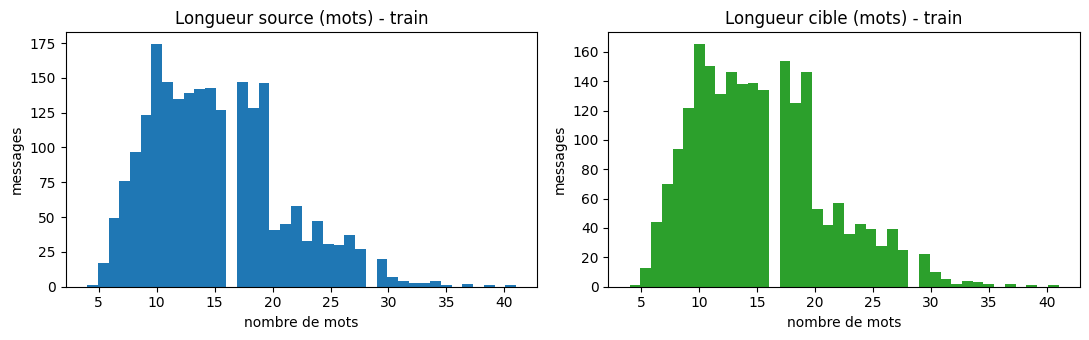

Les deux distributions sont proches : la normalisation change peu la longueur, ce qui facilite le Seq2Seq.


In [8]:
for df in (train_df, dev_df, test_df):
    df["n_src"] = df.source_text.str.split().str.len(); df["n_tgt"] = df.target_text.str.split().str.len()
print("Messages :", {n: len(d) for n, d in [("train", train_df), ("dev", dev_df), ("test", test_df)]})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train_df.n_src, bins=40, color="tab:blue"); axes[0].set_title("Longueur source (mots) - train")
axes[1].hist(train_df.n_tgt, bins=40, color="tab:green"); axes[1].set_title("Longueur cible (mots) - train")
for ax in axes: ax.set_xlabel("nombre de mots"); ax.set_ylabel("messages")
plt.tight_layout(); plt.show()
print("Les deux distributions sont proches : la normalisation change peu la longueur, ce qui facilite le Seq2Seq.")

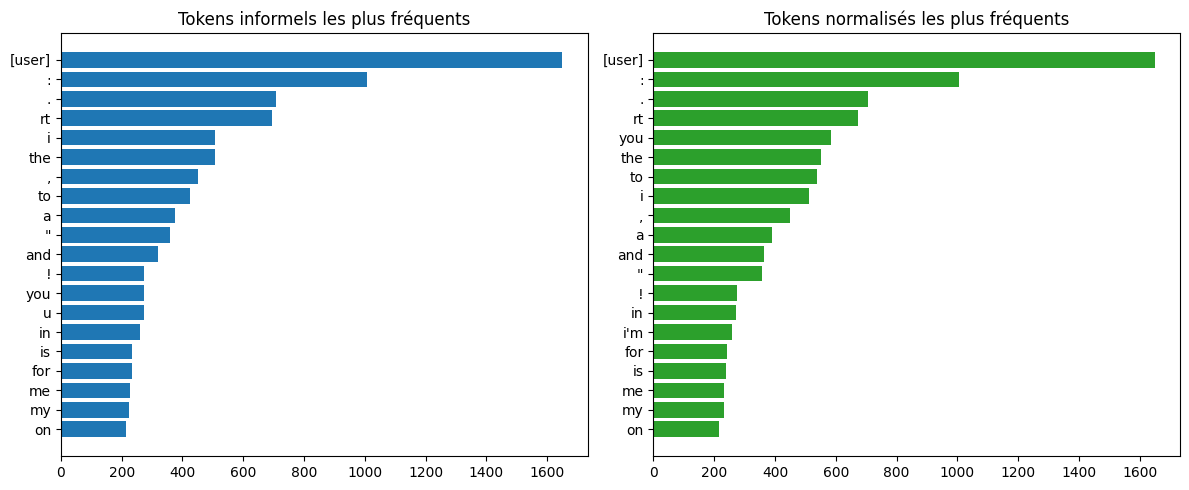

Vocabulaire (mots) source=8555 | cible=7945 : la source est plus riche à cause du bruit.


In [9]:
src_counter = Counter(w for s in train_df.source_text for w in s.split())
tgt_counter = Counter(w for s in train_df.target_text for w in s.split())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, counter, title, color in [(axes[0], src_counter, "Tokens informels les plus fréquents", "tab:blue"),
                                  (axes[1], tgt_counter, "Tokens normalisés les plus fréquents", "tab:green")]:
    words, counts = zip(*counter.most_common(20))
    ax.barh(words[::-1], counts[::-1], color=color); ax.set_title(title)
plt.tight_layout(); plt.show()
print(f"Vocabulaire (mots) source={len(src_counter)} | cible={len(tgt_counter)} : la source est plus riche à cause du bruit.")

In [10]:
all_src_tokens = list(src_counter)
elongated = [w for w in all_src_tokens if re.search(r"(.)\1{2,}", w) and w.isalpha()]
mentions  = [w for w in all_src_tokens if w.startswith("@")]
hashtags  = [w for w in all_src_tokens if w.startswith("#")]
digit_abbr = [w for w in all_src_tokens if re.search(r"[a-z]", w) and re.search(r"\d", w)]
print("Mots allongés      :", elongated[:10]); print("Mentions           :", mentions[:5])
print("Hashtags           :", hashtags[:5]);  print("Abréviations à chiffres:", digit_abbr[:10])

# Statistiques d'alignement : combien de messages sont modifiés par la normalisation ?
differ = train_df[train_df.source_text != train_df.target_text]
print(f"\nMessages où source != cible : {len(differ)} / {len(train_df)} ({len(differ)/len(train_df):.1%})")
display(differ[["source_text", "target_text"]].head(8))

Mots allongés      : ['auchhh', 'thattt', 'raaaaar', 'chukkaeee', 'ahhhh', 'isteeeee', 'xxx', 'naaa', 'nyaaaaa', 'yesshhh']
Mentions           : []
Hashtags           : ['#ballislife', '#amazon', '#basketball', '#2', '#le14']
Abréviations à chiffres: ['http://t.co/gscav8o0ik', 'http://t.co/wbx9h8jndm', 'http://t.co/eybuqyi0ms', 'sm844', '1)buy', 'http://t.co/jlixvido8d', '#le14', 'http://t.co/ffsbrpb2x3', 'wolfnsheepclothing140', 'http://t.co/azde27cbhd']

Messages où source != cible : 1287 / 2186 (58.9%)


,source_text,target_text
0,"rt [user] : "" ah ... [user] : why sub ozil "" [user] : opolo eyes u no fit open eyes """"","rt [user] : "" ah ... [user] : why sub ozil "" [user] : opolo eyes you no fit open eyes """""
1,u have a very sexy header [user] rawr,you have a very sexy header [user] rawr
2,i miss u my bie ! where u wanna out wif me ? have a wonderful day like a swan day .. haha ..,i miss you my bie ! where you want to out with me ? have a wonderful day like a swan day .. haha ..
5,[user] and you didnt make this brah my friend jack storm did :),[user] and you didn't make this brother my friend jack storm did :)
6,[user] [user] pshh i went and got mine done regardless ! ! im sick of not being able to be a girl haha,[user] [user] pshh i went and got mine done regardless ! ! i'm sick of not being able to be a girl haha
8,[user] shit rockin . go head show that to bria .,[user] shit rocking . go head show that to bria .
10,rt [user] : ukip has had two councillors elected in northern ireland today . marvellous .,rt [user] : ukip has had two councillors elected in northern ireland today . marvelous .
11,[user] lol cause i said & you woulda been falling right along with me .,[user] lol because i said & you would have been falling right along with me .


## Section 6 — Tokenisation BPE (sous-mots)
BPE (*Byte Pair Encoding*) fusionne itérativement les paires de symboles les plus fréquentes. Grâce au niveau **octet** (`ByteLevel`), aucun caractère n'est inconnu : mots mal orthographiés, allongements et expressions hors vocabulaire sont décomposés en morceaux connus. **BPE ne normalise pas** : il fournit seulement une représentation numérique du texte ; c'est le Seq2Seq qui apprend la normalisation.

Le tokenizer est entraîné **uniquement sur le train** (sources + cibles), avec un vocabulaire partagé. Tokens spéciaux : `<pad>=0`, `<unk>`, `<bos>`, `<eos>`, `<sep>` (`<sep>` sépare le contexte gauche, le mot à normaliser et le contexte droit).

In [11]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

VOCAB_SIZE = 4000   # corpus petit : un vocabulaire plus petit évite des sous-mots rares jamais appris
SPECIAL_TOKENS = ["<pad>", "<unk>", "<bos>", "<eos>", "<sep>"]

tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, min_frequency=2, special_tokens=SPECIAL_TOKENS,
                              initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False)
tokenizer.train_from_iterator(list(train_df.source_text) + list(train_df.target_text), trainer)   # TRAIN uniquement

PAD_ID, UNK_ID, BOS_ID, EOS_ID, SEP_ID = [tokenizer.token_to_id(t) for t in SPECIAL_TOKENS]
assert (PAD_ID, UNK_ID, BOS_ID, EOS_ID, SEP_ID) == (0, 1, 2, 3, 4), "ids spéciaux inattendus"
VOCAB_ACTUAL = tokenizer.get_vocab_size()
tokenizer.save(str(ARTIFACT_DIR / "tokenizer.json"))
print("Taille réelle du vocabulaire BPE :", VOCAB_ACTUAL)
for text in ["thaaaaaaaaank u for makin me happppy", "idk what u mean lol", "ur gr8", "@someone_new #newtag :)"]:
    enc = tokenizer.encode(text)
    print(f"{text!r}\n   -> {enc.tokens}\n   -> décodage: {tokenizer.decode(enc.ids)!r}")

Taille réelle du vocabulaire BPE : 4000
'thaaaaaaaaank u for makin me happppy'
   -> ['Ġth', 'aa', 'aa', 'aa', 'aa', 'ank', 'Ġu', 'Ġfor', 'Ġmak', 'in', 'Ġme', 'Ġhapp', 'pp', 'y']
   -> décodage: ' thaaaaaaaaank u for makin me happppy'
'idk what u mean lol'
   -> ['Ġidk', 'Ġwhat', 'Ġu', 'Ġmean', 'Ġlol']
   -> décodage: ' idk what u mean lol'
'ur gr8'
   -> ['Ġur', 'Ġgr', '8']
   -> décodage: ' ur gr8'
'@someone_new #newtag :)'
   -> ['Ġ', '@', 's', 'ome', 'one', '_', 'new', 'Ġ#', 'ne', 'wt', 'ag', 'Ġ:)']
   -> décodage: ' @someone_new #newtag :)'


## Section 7 — Seq2Seq au niveau du mot, avec contexte
**Pourquoi ce changement ?** Une première version traitait des tweets entiers : le modèle devait tout recopier mot à mot et inventait des mots (BLEU bien inférieur à la simple copie de la source). Le corpus est **déjà aligné mot à mot** ; on l'exploite : chaque exemple d'entraînement est un mot bruité avec ses 2 voisins de chaque côté, et la cible est son mot normalisé (qui peut contenir plusieurs mots, ex. `idk` → `i do not know`).

Entrée : `contexte gauche <sep> mot <sep> contexte droit <eos>` ; cible décalée pour le teacher forcing : entrée du décodeur `<bos> + cible`, sortie `cible + <eos>`. Mentions et URLs (chaînes aléatoires) sont recopiées sans passer par le modèle. L'architecture (`model_def.py`) reste un Seq2Seq GRU bidirectionnel + attention additive + GRU.

In [12]:
MAX_LEN = 96       # longueur max d'une entrée en sous-mots
CONTEXT = 2        # nombre de mots de contexte de chaque côté
EMB_DIM, HIDDEN_DIM, DROPOUT = 256, 256, 0.3   # réduis à 128/128 si la mémoire GPU est limitée

def collate_batch(batch):
    src, tgt_in, tgt_out = zip(*batch)
    pad = lambda seqs: nn.utils.rnn.pad_sequence([torch.tensor(s) for s in seqs], batch_first=True, padding_value=PAD_ID)
    return pad(src), torch.tensor([len(s) for s in src]), pad(tgt_in), pad(tgt_out)

In [13]:
%%writefile /kaggle/working/normalizer_model/model_def.py
# model_def.py - Seq2Seq (BiGRU encoder + attention + GRU decoder) and text helpers
import re
import torch
import torch.nn as nn

# ---------- Light tokenization / detokenization (same style as the dataset) ----------
TOKEN_REGEX = re.compile(r"https?://\S+|[@#]\w+|[:;=][-o^]?[)(DPp/\\|]|\w+(?:['’]\w+)*|[^\w\s]")

def simple_tokenize(text):
    # Split raw text into tokens: keeps mentions, hashtags, URLs and basic emoticons whole
    return TOKEN_REGEX.findall(text)

def detokenize(text):
    # Cosmetic spacing fix for display only (no space before , . ! ? ; : % ) ])
    text = re.sub(r"\s+([,.!?;:%)\]])", r"\1", text)
    text = re.sub(r"([(\[])\s+", r"\1", text)
    return text.strip()

def is_bypass(token):
    # Mentions and URLs are random strings: they are copied, never sent to the model
    return token == "[user]" or token.startswith(("@", "http://", "https://", "www."))

def make_word_inputs(tokens, encode_word, sep_id, eos_id, context, max_len):
    # One model input per token: left context + <sep> + token + <sep> + right context + <eos>
    inputs = []
    for i, token in enumerate(tokens):
        left = [x for t in tokens[max(0, i - context):i] for x in encode_word(t)][-24:]
        right = [x for t in tokens[i + 1:i + 1 + context] for x in encode_word(t)][:24]
        inputs.append((left + [sep_id] + encode_word(token)[:40] + [sep_id] + right)[:max_len - 1] + [eos_id])
    return inputs

# ---------- Model ----------
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, dropout, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.gru = nn.GRU(emb_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_lens):
        emb = self.dropout(self.embedding(src))                      # (B, S, E)
        packed = nn.utils.rnn.pack_padded_sequence(emb, src_lens.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, h = self.gru(packed)                             # h: (2, B, H)
        out, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True, total_length=src.size(1))
        h = torch.tanh(self.fc(torch.cat([h[0], h[1]], dim=1)))      # (B, H) initial decoder state
        return out, h                                                # out: (B, S, 2H)

class Attention(nn.Module):
    # Additive (Bahdanau) attention
    def __init__(self, hidden_dim):
        super().__init__()
        self.w_enc = nn.Linear(2 * hidden_dim, hidden_dim, bias=False)
        self.w_dec = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, dec_hidden, enc_out, mask):
        energy = self.v(torch.tanh(self.w_enc(enc_out) + self.w_dec(dec_hidden).unsqueeze(1))).squeeze(2)  # (B, S)
        energy = energy.masked_fill(~mask, -1e9)                     # ignore padding positions
        weights = torch.softmax(energy, dim=1)
        context = torch.bmm(weights.unsqueeze(1), enc_out).squeeze(1)  # (B, 2H)
        return context

class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, dropout, pad_id):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.attention = Attention(hidden_dim)
        self.gru = nn.GRU(emb_dim + 2 * hidden_dim, hidden_dim, batch_first=True)
        self.fc_out = nn.Linear(hidden_dim + 2 * hidden_dim + emb_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def step(self, token, hidden, enc_out, mask):
        emb = self.dropout(self.embedding(token))                    # (B, E)
        context = self.attention(hidden, enc_out, mask)              # (B, 2H)
        out, hidden = self.gru(torch.cat([emb, context], dim=1).unsqueeze(1), hidden.unsqueeze(0))
        out, hidden = out.squeeze(1), hidden.squeeze(0)
        logits = self.fc_out(torch.cat([out, context, emb], dim=1))  # (B, V)
        return logits, hidden

class Seq2Seq(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, dropout, pad_id):
        super().__init__()
        self.pad_id = pad_id
        self.encoder = Encoder(vocab_size, emb_dim, hidden_dim, dropout, pad_id)
        self.decoder = Decoder(vocab_size, emb_dim, hidden_dim, dropout, pad_id)

    def forward(self, src, src_lens, tgt_in):
        # Teacher forcing: the decoder always receives the true previous target token
        mask = src != self.pad_id
        enc_out, hidden = self.encoder(src, src_lens)
        step_logits = []
        for t in range(tgt_in.size(1)):
            logits, hidden = self.decoder.step(tgt_in[:, t], hidden, enc_out, mask)
            step_logits.append(logits)
        return torch.stack(step_logits, dim=1)                       # (B, T, V)

    @torch.no_grad()
    def generate(self, src, src_lens, bos_id, eos_id, max_len):
        # Greedy decoding, batched; returns a list of token-id lists (without eos)
        mask = src != self.pad_id
        enc_out, hidden = self.encoder(src, src_lens)
        token = torch.full((src.size(0),), bos_id, dtype=torch.long, device=src.device)
        finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        generated = []
        for _ in range(max_len):                                     # hard limit prevents infinite loops
            logits, hidden = self.decoder.step(token, hidden, enc_out, mask)
            logits[:, self.pad_id] = -1e9
            logits[:, bos_id] = -1e9
            token = logits.argmax(dim=1)
            generated.append(token)
            finished |= token == eos_id
            if finished.all():
                break
        generated = torch.stack(generated, dim=1).tolist()
        results = []
        for ids in generated:
            results.append(ids[:ids.index(eos_id)] if eos_id in ids else ids)
        return results

Writing /kaggle/working/normalizer_model/model_def.py


In [14]:
sys.path.insert(0, str(ARTIFACT_DIR))
from model_def import make_word_inputs, is_bypass

word_cache = {}
def encode_word(word):
    if word not in word_cache: word_cache[word] = tokenizer.encode(word).ids
    return word_cache[word]

def build_word_items(df):
    items, skipped, changed, total = [], 0, 0, 0
    for src_tokens, tgt_tokens in zip(df.src_tokens, df.tgt_tokens):
        if len(src_tokens) != len(tgt_tokens): skipped += 1; continue          # alignement mot à mot impossible
        inputs = make_word_inputs(src_tokens, encode_word, SEP_ID, EOS_ID, CONTEXT, MAX_LEN)
        for src_tok, tgt_tok, src_ids in zip(src_tokens, tgt_tokens, inputs):
            if is_bypass(src_tok): continue
            tgt_ids = encode_word(tgt_tok)[:MAX_LEN - 1]
            items.append((src_ids, [BOS_ID] + tgt_ids, tgt_ids + [EOS_ID]))   # (source, entrée décodeur, sortie attendue)
            total += 1; changed += src_tok != tgt_tok
    return items, skipped, changed / max(total, 1)

train_items, sk_tr, ch_tr = build_word_items(train_df); dev_items, sk_dv, _ = build_word_items(dev_df)
print(f"Exemples mot-à-mot : train={len(train_items)}, dev={len(dev_items)} | messages ignorés: {sk_tr}/{sk_dv}")
print(f"Part des mots modifiés par la normalisation (train) : {ch_tr:.1%}")
ex_src, ex_in, ex_out = train_items[0]
print("Exemple d'entrée :", tokenizer.decode(ex_src[:-1]), "| cible :", tokenizer.decode(ex_out[:-1]))

Exemples mot-à-mot : train=30670, dev=8502 | messages ignorés: 0/0
Part des mots modifiés par la normalisation (train) : 8.5%
Exemple d'entrée :  rt [user] : | cible :  rt


In [15]:
sys.path.insert(0, str(ARTIFACT_DIR))
from model_def import Seq2Seq, simple_tokenize, detokenize

model = Seq2Seq(VOCAB_ACTUAL, EMB_DIM, HIDDEN_DIM, DROPOUT, PAD_ID).to(device)
print("Paramètres entraînables :", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Vérification des dimensions AVANT l'entraînement
src, src_lens, tgt_in, tgt_out = [t.to(device) for t in collate_batch(train_items[:4])]
logits = model(src, src_lens, tgt_in)
print("src", tuple(src.shape), "| src_lens", src_lens.tolist(), "| tgt_in", tuple(tgt_in.shape), "| tgt_out", tuple(tgt_out.shape), "| logits", tuple(logits.shape))
assert logits.shape == (tgt_in.size(0), tgt_in.size(1), VOCAB_ACTUAL), "dimension des logits incorrecte"
assert (tgt_in[:, 0] == BOS_ID).all() and ((tgt_out == EOS_ID).sum(dim=1) == 1).all(), "décalage teacher forcing incorrect"
print("Dimensions et décalage corrects.")

Paramètres entraînables : 8,053,920
src (4, 10) | src_lens [8, 10, 10, 10] | tgt_in (4, 2) | tgt_out (4, 2) | logits (4, 2, 4000)
Dimensions et décalage corrects.


## Section 8 — Entraînement
- **Perte** : entropie croisée avec `ignore_index=<pad>` (le padding ne compte pas).
- **Optimiseur** : Adam, `LEARNING_RATE=1e-3`, écrêtage du gradient (`CLIP=1.0`) pour éviter les gradients explosifs.
- **Sélection** : le **dev** sert uniquement à choisir le meilleur checkpoint (perte de validation minimale) et à l'arrêt anticipé (`PATIENCE`).
- Si l'entraînement est trop lent ou manque de mémoire : réduire `BATCH_SIZE`, `EMB_DIM`/`HIDDEN_DIM` (Section 7) ou `EPOCHS`.

In [16]:
BATCH_SIZE, LEARNING_RATE, EPOCHS, PATIENCE, CLIP = 256, 1e-3, 15, 3, 1.0

g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch, generator=g)
dev_loader   = DataLoader(dev_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

config = dict(vocab_size=VOCAB_ACTUAL, emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM, dropout=DROPOUT, max_len=MAX_LEN, context=CONTEXT,
              pad_id=PAD_ID, unk_id=UNK_ID, bos_id=BOS_ID, eos_id=EOS_ID, sep_id=SEP_ID,
              batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE, clip=CLIP, seed=SEED,
              special_tokens=SPECIAL_TOKENS, preprocessing="NFC + whitespace; no lowercasing; mentions -> [user]; word-level seq2seq with context")

def run_epoch(loader, train):
    model.train(train); total, n_batches = 0.0, 0
    with torch.set_grad_enabled(train):
        for src, src_lens, tgt_in, tgt_out in loader:
            src, src_lens, tgt_in, tgt_out = src.to(device), src_lens.to(device), tgt_in.to(device), tgt_out.to(device)
            logits = model(src, src_lens, tgt_in)
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt_out.reshape(-1))
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)      # écrêtage du gradient
                optimizer.step()
            total += loss.item(); n_batches += 1
    return total / n_batches

history, best_val, bad_epochs = [], float("inf"), 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(dev_loader, train=False)
    history.append((epoch, train_loss, val_loss))
    improved = val_loss < best_val
    if improved:
        best_val, bad_epochs = val_loss, 0
        torch.save(model.state_dict(), ARTIFACT_DIR / "best_model.pt")
        config.update(best_epoch=epoch, best_val_loss=best_val)
        (ARTIFACT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
    else:
        bad_epochs += 1
    print(f"Epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} (ppl {np.exp(val_loss):.2f}) | {time.time()-t0:5.1f}s {'<- meilleur' if improved else ''}")
    if bad_epochs >= PATIENCE:
        print(f"Arrêt anticipé : pas d'amélioration depuis {PATIENCE} époques."); break
print(f"Meilleure perte de validation : {best_val:.4f} (époque {config['best_epoch']})")

Epoch  1 | train 3.3163 | val 1.4024 (ppl 4.06) |   8.4s <- meilleur
Epoch  2 | train 0.8631 | val 0.4620 (ppl 1.59) |   7.7s <- meilleur
Epoch  3 | train 0.3012 | val 0.3245 (ppl 1.38) |   7.9s <- meilleur
Epoch  4 | train 0.1589 | val 0.2984 (ppl 1.35) |   8.0s <- meilleur
Epoch  5 | train 0.1103 | val 0.2721 (ppl 1.31) |   8.1s <- meilleur
Epoch  6 | train 0.0873 | val 0.2846 (ppl 1.33) |   8.1s 
Epoch  7 | train 0.0692 | val 0.2725 (ppl 1.31) |   8.1s 
Epoch  8 | train 0.0536 | val 0.2642 (ppl 1.30) |   8.3s <- meilleur
Epoch  9 | train 0.0411 | val 0.2631 (ppl 1.30) |   8.5s <- meilleur
Epoch 10 | train 0.0357 | val 0.2637 (ppl 1.30) |   8.5s 
Epoch 11 | train 0.0340 | val 0.2853 (ppl 1.33) |   8.6s 
Epoch 12 | train 0.0310 | val 0.2765 (ppl 1.32) |   8.5s 
Arrêt anticipé : pas d'amélioration depuis 3 époques.
Meilleure perte de validation : 0.2631 (époque 9)


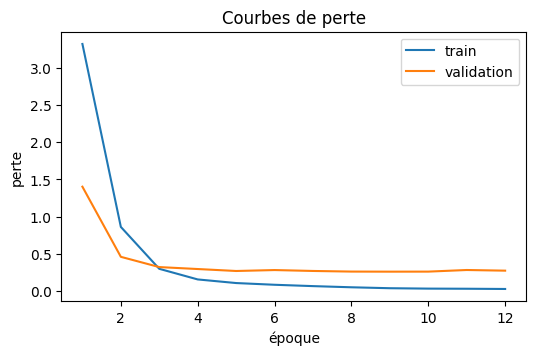

In [17]:
epochs_, tr_, va_ = zip(*history)
plt.figure(figsize=(6, 3.5)); plt.plot(epochs_, tr_, label="train"); plt.plot(epochs_, va_, label="validation")
plt.xlabel("époque"); plt.ylabel("perte"); plt.title("Courbes de perte"); plt.legend(); plt.show()

## Section 9 — Inférence et décodage
`inference.py` (même fichier pour Streamlit) : `normalize_text(text)` découpe le message en tokens (mentions, hashtags, ponctuation conservés), construit pour chaque mot son entrée avec contexte, encode avec le BPE sauvegardé, génère la sortie **de façon autorégressive (glouton)** jusqu'à `<eos>` ou une longueur maximale, décode, puis assemble le message et rétablit l'espacement de la ponctuation. Mentions et URLs sont recopiées telles quelles. Entrée vide → chaîne vide ; entrée très longue → tronquée à 200 tokens.

In [18]:
%%writefile /kaggle/working/normalizer_model/inference.py
# inference.py - independent inference: load artifacts and expose normalize_text(text)
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))   # so that model_def is importable

import torch
from tokenizers import Tokenizer
from model_def import Seq2Seq, simple_tokenize, detokenize, is_bypass, make_word_inputs

MAX_TOKENS = 200   # very long messages are truncated to this many tokens

def load_normalizer(artifact_dir, device=None):
    artifact_dir = Path(artifact_dir)
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    cfg = json.loads((artifact_dir / "config.json").read_text(encoding="utf-8"))
    tokenizer = Tokenizer.from_file(str(artifact_dir / "tokenizer.json"))
    model = Seq2Seq(cfg["vocab_size"], cfg["emb_dim"], cfg["hidden_dim"], cfg["dropout"], cfg["pad_id"]).to(device)
    model.load_state_dict(torch.load(artifact_dir / "best_model.pt", map_location=device))
    model.eval()
    pad_id, bos_id, eos_id, sep_id = cfg["pad_id"], cfg["bos_id"], cfg["eos_id"], cfg["sep_id"]
    max_len, context = cfg["max_len"], cfg["context"]
    cache = {}

    def encode_word(word):
        if word not in cache:
            cache[word] = tokenizer.encode(word).ids
        return cache[word]

    def run_model(inputs, batch_size):
        # Greedy decoding of every input; sorted by length for speed, results returned in original order
        outputs = [""] * len(inputs)
        order = sorted(range(len(inputs)), key=lambda i: len(inputs[i]))
        for start in range(0, len(order), batch_size):
            idx = order[start:start + batch_size]
            ids_list = [inputs[i] for i in idx]
            lens = torch.tensor([len(x) for x in ids_list])
            src = torch.full((len(ids_list), int(lens.max())), pad_id, dtype=torch.long)
            for row, ids in enumerate(ids_list):
                src[row, :len(ids)] = torch.tensor(ids)
            limit = min(max_len, int(lens.max()) * 2 + 10)           # prevents endless generation
            generated = model.generate(src.to(device), lens.to(device), bos_id, eos_id, limit)
            for i, ids in zip(idx, generated):
                outputs[i] = tokenizer.decode(ids).strip()
        return outputs

    def normalize_tokens_batch(token_lists, batch_size=512):
        # token_lists: list of messages, each a list of tokens. Returns one output string per token.
        inputs, owners = [], []
        for m, tokens in enumerate(token_lists):
            context_tokens = ["[user]" if t.startswith("@") else t for t in tokens]
            word_inputs = make_word_inputs(context_tokens, encode_word, sep_id, eos_id, context, max_len)
            for i, ids in enumerate(word_inputs):
                if not is_bypass(tokens[i]):
                    inputs.append(ids); owners.append((m, i))
        predictions = run_model(inputs, batch_size)
        outputs = [list(tokens) for tokens in token_lists]            # mentions/URLs keep themselves
        for (m, i), prediction in zip(owners, predictions):
            outputs[m][i] = prediction
        return outputs

    def normalize_batch(texts, pretokenized=False, detok=True, batch_size=512):
        token_lists = []
        for text in texts:
            text = " ".join(str(text).split())
            tokens = text.split() if pretokenized else simple_tokenize(text)
            token_lists.append(tokens[:MAX_TOKENS])
        results = []
        for out in normalize_tokens_batch(token_lists, batch_size):
            joined = " ".join(w for w in out if w)
            results.append(detokenize(joined) if detok else joined)    # empty input -> ""
        return results

    def normalize_text(text, detok=True):
        return normalize_batch([text], detok=detok)[0]

    normalize_text.batch = normalize_batch
    normalize_text.tokens = normalize_tokens_batch
    return normalize_text

Writing /kaggle/working/normalizer_model/inference.py


In [19]:
from inference import load_normalizer
normalize_text = load_normalizer(ARTIFACT_DIR, device=device)   # recharge le MEILLEUR checkpoint (pas le dernier)

print("=== Exemples du DEV : prédictions réelles du modèle vs références ===")
rows = dev_df.sample(8, random_state=SEED)
preds = normalize_text.batch(rows.source_text.tolist(), pretokenized=True, detok=False)
display(pd.DataFrame({"source": rows.source_text.values, "référence (dataset)": rows.target_text.values, "prédiction (modèle)": preds}))

print("=== Messages écrits à la main : prédictions du modèle (pas de référence) ===")
for msg in ["thx u so much", "ur gr8", "thaaaaaaaaank u", "idk what u mean lol", "", "@bob omg luv this song !!!"]:
    print(f"{msg!r:35} -> {normalize_text(msg)!r}")
print("Entrée très longue :", len(normalize_text("lol " * 500)), "caractères en sortie (aucune boucle infinie).")

=== Exemples du DEV : prédictions réelles du modèle vs références ===


,source,référence (dataset),prédiction (modèle)
0,rt [user] : half a million in my duffel bag ! now i'm ridin in my duramax .,rt [user] : half a million in my duffel bag ! now i'm riding in my duramax .,rt [user] : half a million in my duffel bag ! now i'm riding in my duramax .
1,jst read a tweet and it made me say ew,just read a tweet and it made me say ew,just read a tweet and it made me say ew
2,rt [user] : be careful you don't ' comment ' ' like ' ' retweet ' ' repost ' and ' selfie ' your life away .,rt [user] : be careful you don't ' comment ' ' like ' ' retweet ' ' repost ' and ' selfie ' your life away .,rt [user] : be careful you don't ' comment ' ' like ' ' retweet ' ' repost ' and ' selfie ' your life away .
3,who gets rejected from mcdonalds ? lol,who gets rejected from mcdonalds ? lol,who gets rehected from mamonal ? lol
4,[user] ehh ehh wait wait ~ jap kenal ain ?,[user] ehh ehh wait wait ~ jap kenal ain ?,[user] ehh ehh wait wait ~ and kenal are ?
5,"she is still president so whatever she says is valid "" [user] : section 82 sikugwirizana ndi zomwe jb akukamba apa s...","she is still president so whatever she says is valid "" [user] : section 82 sikugwirizana ndi zomwe jb akukamba apa s...","she is still president so what she says is valid "" [user] : section 82 sikugwirs ndi zomwe jb akukamba apa shaah """
6,"meilleures ventes - #3 : izak of lapland : izak of lapland maya angelou ( auteur ) , l ... http://t.co/ix6kgbbdoz st...","meilleures ventes - #3 : izak of lapland : izak of lapland maya angelou ( auteur ) , l ... http://t.co/ix6kgbbdoz st...","meille ventes - #3 : izak of lapland : izak of lapland maya angelou ( auteur ) , l ... http://t.co/ix6kgbbdoz store ..."
7,"diarmuid o flynn "" eliminated but a great campaign "" . 51,387 votes . #eurosouth #tv3news http://t.co/kmtmpywz6z","diarmuid o flynn "" eliminated but a great campaign "" . 51,387 votes . #eurosouth #tv3news http://t.co/kmtmpywz6z","diarashtid o flynn "" eliminated but a great campaign "" . 51,387 votes . #eurosouth #tv3news http://t.co/kmtmpywz6z"


=== Messages écrits à la main : prédictions du modèle (pas de référence) ===
'thx u so much'                     -> 'thanks you so much'
'ur gr8'                            -> "you're gr8"
'thaaaaaaaaank u'                   -> 'thaaaaaaaaank you'
'idk what u mean lol'               -> 'idk what you mean lol'
''                                  -> ''
'@bob omg luv this song !!!'        -> '@bob omg love this song!!!'
Entrée très longue : 799 caractères en sortie (aucune boucle infinie).


## Section 10 — Évaluation sur le test
Trois mesures sur le test (jamais utilisé pour entraîner ni choisir les hyperparamètres) :
- **BLEU SacreBLEU** (corpus, messages complets, `tokenize="none"` car le texte est déjà tokenisé) ;
- **Précision par token** : part des tokens dont la sortie égale la référence ;
- **ERR** (*Error Reduction Rate*) = (précision modèle − précision copie) / (1 − précision copie) : fraction des erreurs de la simple copie que le modèle corrige. C'est la métrique usuelle des campagnes d'évaluation de normalisation lexicale ; > 0 signifie que le modèle fait mieux que ne rien faire.
La ligne de base « copier la source » est indispensable : la plupart des tokens ne changent pas.

In [20]:
try:
    import sacrebleu
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)   # nécessite Internet activé
    import sacrebleu
from sacrebleu.metrics import BLEU
corpus_bleu = BLEU(tokenize="none", force=True); sentence_bleu = BLEU(tokenize="none", effective_order=True, force=True)

test_src_tokens, test_tgt_tokens = list(test_df.src_tokens), list(test_df.tgt_tokens)
test_sources, test_refs = test_df.source_text.tolist(), test_df.target_text.tolist()
start = time.time()
test_pred_tokens = normalize_text.tokens(test_src_tokens)          # une sortie par token source
batch_seconds = time.time() - start
test_preds = [" ".join(w for w in out if w) for out in test_pred_tokens]
assert len(test_preds) == len(test_refs)

print("BLEU test (modèle)            :", corpus_bleu.corpus_score(test_preds, [test_refs]))
print("BLEU test (copie de la source):", corpus_bleu.corpus_score(test_sources, [test_refs]), " <- repère minimal")
unseen = ~test_df.source_text.isin(sources["train"]).values
if unseen.any():
    print(f"BLEU test, sources absentes du train ({unseen.sum()} msgs):",
          corpus_bleu.corpus_score([p for p, u in zip(test_preds, unseen) if u], [[r for r, u in zip(test_refs, unseen) if u]]))

# Métriques par token (messages dont source et cible ont le même nombre de tokens)
aligned = [m for m in range(len(test_df)) if len(test_src_tokens[m]) == len(test_tgt_tokens[m])]
triples = [(s, r, p) for m in aligned for s, r, p in zip(test_src_tokens[m], test_tgt_tokens[m], test_pred_tokens[m])]
n_tok = len(triples)
acc_model = sum(p == r for s, r, p in triples) / n_tok
acc_copy  = sum(s == r for s, r, p in triples) / n_tok
err = (acc_model - acc_copy) / (1 - acc_copy)
changed = [(s, r, p) for s, r, p in triples if s != r]
print(f"\nTokens évalués : {n_tok} ({len(aligned)}/{len(test_df)} messages alignés)")
print(f"Précision par token : modèle {acc_model:.2%} | copie {acc_copy:.2%} | ERR = {err:.1%}")
print(f"Mots à normaliser correctement normalisés : {sum(p == r for s, r, p in changed) / len(changed):.1%} ({len(changed)} tokens)")
print(f"Mots à garder correctement gardés         : {sum(p == r for s, r, p in triples if s == r) / (n_tok - len(changed)):.1%}")

t0 = time.time()
for s in test_sources[:50]: normalize_text.batch([s], pretokenized=True, detok=False)
print(f"\nTemps moyen: {1000*batch_seconds/len(test_sources):.2f} ms/message (par lots) | {1000*(time.time()-t0)/50:.1f} ms/message (un par un)")

results = pd.DataFrame({"source": test_sources, "référence": test_refs, "prédiction": test_preds})
results["bleu_phrase"] = [sentence_bleu.sentence_score(p, [r]).score for p, r in zip(test_preds, test_refs)]
display(results.sample(8, random_state=SEED))

BLEU test (modèle)            : BLEU = 86.97 94.5/89.5/84.8/80.6 (BP = 0.997 ratio = 0.997 hyp_len = 29419 ref_len = 29497)
BLEU test (copie de la source): BLEU = 81.28 92.2/85.1/79.0/73.6 (BP = 0.989 ratio = 0.989 hyp_len = 29180 ref_len = 29497)  <- repère minimal
BLEU test, sources absentes du train (1933 msgs): BLEU = 86.81 94.4/89.3/84.6/80.4 (BP = 0.997 ratio = 0.997 hyp_len = 29010 ref_len = 29087)

Tokens évalués : 29180 (1954/1954 messages alignés)
Précision par token : modèle 94.56% | copie 92.20% | ERR = 30.3%
Mots à normaliser correctement normalisés : 67.9% (2276 tokens)
Mots à garder correctement gardés         : 96.8%

Temps moyen: 0.98 ms/message (par lots) | 6.0 ms/message (un par un)


,source,référence,prédiction,bleu_phrase
1617,"lol , i knew it wasnt gone be long before she changed her header !!","lol , i knew it wasn't gone be long before she changed her header !!","lol , i knew it wasn't gone be long before she changed her header !!",100.000000
1731,"rt [user] : welcome to pusamania borneo , amadeus suropati . #jendelatransfer","rt [user] : welcome to pusamania borneo , amadeus suropati . #jendelatransfer","rt [user] : welim to pusamania borneo , amadeus suropati . #jendelatrans",63.404663
976,[user] [user] yupp !! its a good move for luiz imo because jm didnt want him in his xi so good luck to him .,[user] [user] yupp !! it's a good move for luiz imo because jm didn't want him in his xi so good luck to him .,[user] [user] you !! its a good move for luiz imo because jm didn't want him in his xi so good luck to him .,82.517179
1057,[user] dat nikkar calld god gave it to me for a reason .. yeap i believe in it niiiikkkaaarrr,[user] that nigger called god gave it to me for a reason .. yeap i believe in it niiiikkkaaarrr,[user] that nikkar calld god gave it to me for a reason .. yeap i believe in it niggeriiikkkarar,75.085614
307,we are one ( ole ola ) [ the official 2014 fifa world cup song ] ( olodum mix ... : http://t.co/nq2wmdcgwz via [user],we are one ( ole ola ) [ the official 2014 fifa world cup song ] ( olodum mix ... : http://t.co/nq2wmdcgwz via [user],we are one ( ole ola ) [ the official 2014 fifa world cup song ] ( olodum mix ... : http://t.co/nq2wmdcgwz via [user],100.000000
432,rt [user] : ha = mildly amusing haha = quite funny haha = i am actually laughing haja = i am doing karate,rt [user] : ha = mildly amusing haha = quite funny haha = i am actually laughing haja = i am doing karate,rt [user] : ha = mildly amusing haha = quite funny haha = i am actually laughing haja = i am doing karate,100.000000
1469,"if youre leaving the fandom bc zouis smoking pot i laugh at you , pick ur balls up","if you're leaving the fandom because zouis smoking pot i laugh at you , pick your balls up","if you're leaving the fandom because zouis smoking pot i laugh at you , pick you're balls up",85.789281
599,a wondrful celebration ... tnk y'all 4 cumin,a wonderful celebration ... thank y'all for coming,a wondrful celebration ... tnk y'all 4 cumin,13.134549


**Limites de BLEU pour la normalisation.** BLEU compare des n-grammes exacts : une prédiction raisonnable (autre ponctuation, casse différente, formulation équivalente) est pénalisée, et inversement un message presque identique à la source obtient déjà un score élevé car la majorité des tokens ne change pas. Il faut donc le lire avec la ligne de base « copie de la source » et avec l'analyse d'erreurs.

## Section 11 — Analyse d'erreurs
Comme la sortie est alignée mot à mot, on compare **token par token** les vraies prédictions du test. Chaque erreur est typée : *sur-normalisation* (le mot devait rester identique), *normalisation manquée* (le mot a été recopié alors qu'il fallait le changer) ou *mauvaise normalisation*. Le token source est catégorisé par règles simples (analyse uniquement) ; « dépendant du contexte » = token ayant plusieurs cibles fréquentes dans le train. La colonne *explication* est générée par règle : relis-la et complète-la à la main pour ton rapport.

In [21]:
mapping = defaultdict(Counter)
for s_tok, t_tok in zip(train_df.src_tokens, train_df.tgt_tokens):
    if len(s_tok) == len(t_tok):
        for a, b in zip(s_tok, t_tok): mapping[a][b] += 1
ambiguous = {w for w, c in mapping.items() if len(c) >= 2 and sorted(c.values())[-2] / sum(c.values()) >= 0.10}

def categorize(src_tok):
    if src_tok.startswith(("@", "#", "http")) or src_tok == "[user]": return "mention/hashtag/URL"
    if re.search(r"(.)\1{2,}", src_tok): return "mot allongé"
    if not any(ch.isalnum() for ch in src_tok): return "ponctuation/symbole"
    if src_tok in ambiguous: return "dépendant du contexte"
    if re.search(r"[a-z]", src_tok) and re.search(r"\d", src_tok): return "abréviation (chiffres)"
    if len(src_tok) <= 4: return "abréviation / forme courte"
    return "faute d'orthographe / autre"

EXPLAIN = {
    "mention/hashtag/URL": "Hashtag ou symbole modifié alors qu'il devait rester identique.",
    "mot allongé": "Réduction de la répétition vers un mot incorrect ou non appris.",
    "ponctuation/symbole": "Symbole ou ponctuation mal traité.",
    "dépendant du contexte": "Token à plusieurs normalisations dans le train : mauvais choix selon le contexte.",
    "abréviation (chiffres)": "Abréviation avec chiffres mal développée.",
    "abréviation / forme courte": "Forme courte mal développée (rare ou ambiguë).",
    "faute d'orthographe / autre": "Mot non corrigé ou corrigé vers un mauvais mot.",
}
rows = []
for m in aligned:
    s_toks, r_toks, p_toks = test_src_tokens[m], test_tgt_tokens[m], test_pred_tokens[m]
    for i, (s, r, p) in enumerate(zip(s_toks, r_toks, p_toks)):
        if r == p: continue
        kind = "sur-normalisation" if s == r else ("normalisation manquée" if p == s else "mauvaise normalisation")
        cat = categorize(s)
        rows.append(dict(msg=m, token_source=s, référence=r, prédiction=p, type=kind, catégorie=cat,
                         explication=f"'{s}' -> attendu '{r}', prédit '{p}' ({kind}). {EXPLAIN[cat]}"))
tok_err = pd.DataFrame(rows)
print(f"Erreurs par token : {len(tok_err)} sur {n_tok} ({len(tok_err)/n_tok:.2%})")
print(tok_err.type.value_counts().to_string()); print(); print(tok_err.catégorie.value_counts().to_string())

first = tok_err.drop_duplicates("msg").copy()          # une erreur représentative par message
first["source"] = [test_sources[m] for m in first.msg]; first["référence_msg"] = [test_refs[m] for m in first.msg]
first["prédiction_msg"] = [test_preds[m] for m in first.msg]
err_df = first.rename(columns={"catégorie": "catégorie"})
table = err_df.groupby("catégorie", group_keys=False).apply(lambda d: d.head(2))
display(table[["source", "référence_msg", "prédiction_msg", "catégorie", "explication"]].reset_index(drop=True))

Erreurs par token : 1587 sur 29180 (5.44%)
type
sur-normalisation         857
normalisation manquée     546
mauvaise normalisation    184

catégorie
faute d'orthographe / autre    756
abréviation / forme courte     410
dépendant du contexte          168
mention/hashtag/URL            148
mot allongé                     52
abréviation (chiffres)          45
ponctuation/symbole              8


/tmp/ipykernel_23/160137881.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table = err_df.groupby("catégorie", group_keys=False).apply(lambda d: d.head(2))


,source,référence_msg,prédiction_msg,catégorie,explication
0,#5 : asus p8b75-m/csm lga 1155 intel b75 hdmi sata 6gb/s usb 3.0 micro atx intel motherboard : asus p8b75-m/csm lga ...,#5 : asus p8b75-m/csm lga 1155 intel b75 hdmi sata 6gb/s usb 3.0 micro atx intel motherboard : asus p8b75-m/csm lga ...,#5 : asus p8b5-sx018mmm lga 1155 intel b75 hdmi sata 6 usb 3.0 micro atx intel motherboard : asus p8b5-sx018mmm lga ...,abréviation (chiffres),"'p8b75-m/csm' -> attendu 'p8b75-m/csm', prédit 'p8b5-sx018mmm' (sur-normalisation). Abréviation avec chiffres mal dé..."
1,"http://t.co/wblm0khxzg #2 : proctor silex k2070ya electric kettle , 1-liter proctor silex k2070ya electric kettl ......","http://t.co/wblm0khxzg #2 : proctor silex k2070ya electric kettle , 1-liter proctor silex k2070ya electric kettl ......","http://t.co/wblm0khxzg #2 : proctor silex k2070ya electric kettle , 1-aler proctor silex k2070ya electric kettl ... ...",abréviation (chiffres),"'1-liter' -> attendu '1-liter', prédit '1-aler' (sur-normalisation). Abréviation avec chiffres mal développée."
2,[user] yeh but still that's wild lol,[user] yeah but still that's wild lol,[user] yeh but still that's wild lol,abréviation / forme courte,"'yeh' -> attendu 'yeah', prédit 'yeh' (normalisation manquée). Forme courte mal développée (rare ou ambiguë)."
3,[user] [user] [user] card in 5 mins is with wh but this was the game so far bk lol but how to find who the ref is,[user] [user] [user] card in 5 minutes is with wh but this was the game so far bk lol but how to find who the ref is,[user] [user] [user] card in 5 minutes is with wh but this was the game so far bulk lol but how to find who the ref is,abréviation / forme courte,"'bk' -> attendu 'bk', prédit 'bulk' (sur-normalisation). Forme courte mal développée (rare ou ambiguë)."
4,"with your beleive , u must receive , soo don't be deceived , with god , all things are possible . #hapibufdedamooz","with your beleive , you must receive , so don't be deceived , with god , all things are possible . #hapibufdedamooz","with your beleive , you must receive , soo don't be deceived , with god , all things are possible . #hapagtouramzonez",dépendant du contexte,"'soo' -> attendu 'so', prédit 'soo' (normalisation manquée). Token à plusieurs normalisations dans le train : mauvai..."
5,[user] hahaaa .!! you probs didn't even realise there was anything wrong with it hahaa .!! xxx,[user] hahaaa .!! you probably didn't even realise there was anything wrong with it hahaa .!! xxx,[user] hahaaa .!! you problems didn't even realize there was anything wrong with it hahaa .!! xxx,dépendant du contexte,"'probs' -> attendu 'probably', prédit 'problems' (mauvaise normalisation). Token à plusieurs normalisations dans le ..."
6,"dick in janice , im poppin xanax and speakin spanish .","dick in janice , i'm popping xanax and speaking spanish .","dick in janice , i'm popping xanax and lakin spanish .",faute d'orthographe / autre,"'speakin' -> attendu 'speaking', prédit 'lakin' (mauvaise normalisation). Mot non corrigé ou corrigé vers un mauvais..."
7,samsung working on oculus rift-like vr headsets for galaxy devices : report - firstpost http://t.co/bfynj5fktt,samsung working on oculus rift-like vr headsets for galaxy devices : report - firstpost http://t.co/bfynj5fktt,samsung working on oculus rift-16 vr headsets for galaxy devices : report - firstpost http://t.co/bfynj5fktt,faute d'orthographe / autre,"'rift-like' -> attendu 'rift-like', prédit 'rift-16' (sur-normalisation). Mot non corrigé ou corrigé vers un mauvais..."
8,enter to #win a prize pack of lindor truffles and lindor sticks ( arcv $52 ) from lindt & [user] ! #giveaway http://...,enter to #win a prize pack of lindor truffles and lindor sticks ( arcv $52 ) from lindt & [user] ! #giveaway http://...,enter to #w a prize pack of lindor truffles and lindor sticks ( ar $52 ) from lindt & [user] ! #giveaway http://t.co...,mention/hashtag/URL,"'#win' -> attendu '#win', prédit '#w' (sur-normalisation). Has

In [22]:
# Les 10 messages les plus mal prédits (BLEU de phrase le plus bas) : à relire à la main pour repérer les changements de sens
display(results.sort_values("bleu_phrase").head(10)[["source", "référence", "prédiction", "bleu_phrase"]])

,source,référence,prédiction,bleu_phrase
1320,campeones oe campeones oe campeones oe campeones eoe,campeones oe campeones oe campeones oe campeones eoe,campe's oe campeci oe campeci oe campeci eoe,7.809850
1162,dentist appt and now dermatologist appt = hella waiting -_-,dentist appointment and now dermatologist appointment = hell of a lot of waiting -_-,dentist appo and now dermatolog appointment = hella waiting -_-,10.126442
1903,#bqetraffic acc eb btw hamilton av & brklyn brdg . rt ln blkd ! #brooklyntraffic #queenstraffic http://t.co/ocurmqwgbu,#bqetraffic acc eb btw hamilton avenue & brooklyn bridge . retweet lane blocked ! #brooklyntraffic #queenstraffic ht...,#wmaetraffic accident eb btw hamilton av & brklyn brdg . retweet ln bl you ! #brooklynraffic #queenstraffic http://t...,12.512237
1080,goji and grapefruit amaretti biscuit recipe http://t.co/rtsvf5l0jo,goji and grapefruit amaretti biscuit recipe http://t.co/rtsvf5l0jo,go's and grape frontuit amaretti bis recipe http://t.co/rtsvf5l0jo,13.134549
599,a wondrful celebration ... tnk y'all 4 cumin,a wonderful celebration ... thank y'all for coming,a wondrful celebration ... tnk y'all 4 cumin,13.134549
531,[user] aawww nowt wrong with tgat x,[user] aawww nothing wrong with that x,[user] aawlam nowt wrong with tgat x,15.619700
929,britains got talent is soo shite this year,britains got talent is so shitty this year,britains got taylorent is soo sh this year,16.515822
741,drinking a grimbergen dubbel by brouwerij alken-maes - http://t.co/nqo2u3rq60,drinking a grimbergen dubbel by brouwerij alken-maes - http://t.co/nqo2u3rq60,drinking a grimberry dubbel by brouwishj alken-mamaes - http://t.co/nqo2u3rq60,16.515822
1329,[user] #30thmay2014 #werememberthem 3.5 millionbiafrans killed by nigeriangovt 1967-70genocide sponsored b britishgo...,[user] #30thmay2014 #werememberthem 3.5 million biafrans killed by nigeriangovt 1967-70genocide sponsored by british...,[user] #30thmay #weremidthem 3.5 millionbiaatans killed by nigeriangofe 1967-sx018 sponsored b britishgo please supp...,17.781797
1115,http://t.co/rm1beox3zc sunny new colections 5 720p 1.68 gb ddh ~ rg em ~ alone,http://t.co/rm1beox3zc sunny new collections 5 720p 1.68 gb ddh ~ rg em ~ alone,http://t.co/rm1beox3zc sunny new co 5 720p 1.2 gb dxck ~ rg them ~ alone,17.960717


**Limites** (à discuter avec les résultats ci-dessus) : (1) *Données* : corpus de taille limitée et de domaine unique (Twitter) ; les références ne sont pas toujours cohérentes. (2) *BPE* : un mot rare ou très allongé est coupé en sous-mots peu informatifs, ce qui rend l'apprentissage plus difficile. (3) *Seq2Seq GRU* : petite capacité, décodage glouton, risque d'hallucination ou de changement de sens sur des phrases rares ; les mentions/URLs inconnues peuvent être altérées.

## Section 12 — Sauvegarde et export
Tous les artefacts sont dans `ARTIFACT_DIR` : `best_model.pt`, `config.json` (hyperparamètres + ids spéciaux + longueur max), `tokenizer.json`, `model_def.py`, `inference.py`. On vérifie ensuite qu'un **nouveau** modèle chargé depuis ces fichiers donne les mêmes prédictions, puis on crée le ZIP. Les données d'entraînement ne sont pas exportées.

In [23]:
expected = ["best_model.pt", "config.json", "tokenizer.json", "model_def.py", "inference.py"]
missing = [f for f in expected if not (ARTIFACT_DIR / f).exists()]
assert not missing, f"Artefacts manquants: {missing}"

fresh_normalize = load_normalizer(ARTIFACT_DIR, device="cpu")          # nouvelle instance du modèle, sur CPU
check = dev_df.source_text.head(10).tolist()
a = normalize_text.batch(check, pretokenized=True, detok=False); b = fresh_normalize.batch(check, pretokenized=True, detok=False)
print("Rechargement identique :", a == b)
if a != b: print("Différences mineures possibles entre GPU et CPU (arrondis) ; vérifie les exemples.")
print("Exemple après rechargement:", fresh_normalize("thx u 4 the follow"))

zip_path = shutil.make_archive(str(WORKING_DIR / "normalizer_model"), "zip", root_dir=WORKING_DIR, base_dir="normalizer_model")
print("Archive créée :", zip_path, f"({Path(zip_path).stat().st_size/1e6:.1f} Mo)")

Rechargement identique : True
Exemple après rechargement: thanks you 4 the follow
Archive créée : /kaggle/working/normalizer_model.zip (29.9 Mo)


## Section 13 — Démo Streamlit
`app.py` charge le modèle et le tokenizer depuis `normalizer_model/` (jamais d'entraînement au démarrage), tourne sur CPU et affiche une erreur claire si les artefacts manquent. Pour la tester localement : `streamlit run app.py`.

In [24]:
%%writefile /kaggle/working/hf_space/app.py
# app.py - Streamlit demo (CPU, no training at startup)
import sys
from pathlib import Path

import streamlit as st

ARTIFACT_DIR = Path(__file__).resolve().parent / "normalizer_model"
REQUIRED_FILES = ["best_model.pt", "tokenizer.json", "config.json", "model_def.py", "inference.py"]

st.set_page_config(page_title="Informal Text Normalizer", page_icon="💬", layout="wide")
st.title("💬 Informal Text Normalizer")
st.markdown(
    "Transforme des messages informels (Twitter / chat) en anglais normalisé grâce à un modèle "
    "**Seq2Seq GRU + attention** entraîné sur tokenisation **BPE**.  \n"
    "*Turns informal Twitter/chat English into normalized English (BPE + GRU Seq2Seq with attention).*"
)

missing = [name for name in REQUIRED_FILES if not (ARTIFACT_DIR / name).exists()]
if missing:
    st.error(
        f"Fichiers du modèle introuvables dans `{ARTIFACT_DIR}` : {', '.join(missing)}.\n\n"
        "Téléversez le dossier `normalizer_model/` (issu du notebook Kaggle) à côté de `app.py`."
    )
    st.stop()

@st.cache_resource(show_spinner="Chargement du modèle...")
def get_normalizer():
    sys.path.insert(0, str(ARTIFACT_DIR))
    from inference import load_normalizer
    return load_normalizer(ARTIFACT_DIR, device="cpu")

normalize_text = get_normalizer()

EXAMPLES = [
    "thaaaaaaaaank u for makin me happppy",
    "idk what u mean lol",
    "ur gr8 thx",
    "rt @someone : omg i luv this song !",
]

if "user_text" not in st.session_state:
    st.session_state["user_text"] = EXAMPLES[0]

st.subheader("Exemples")
columns = st.columns(len(EXAMPLES))
for column, example in zip(columns, EXAMPLES):
    if column.button(example, use_container_width=True):
        st.session_state["user_text"] = example

user_text = st.text_area("Message informel", key="user_text", height=120)

if st.button("Normalize", type="primary"):
    if not user_text.strip():
        st.warning("Veuillez saisir un message.")
    else:
        result = normalize_text(user_text)
        left, right = st.columns(2)
        left.markdown("#### Original")
        left.info(user_text)
        right.markdown("#### Normalisé")
        right.success(result if result else "(sortie vide)")

st.caption("Projet universitaire - Youssef Nafae - Normalisation de Texte Informel")

Writing /kaggle/working/hf_space/app.py


## Section 14 — Déploiement sur Hugging Face Spaces
Kaggle et Hugging Face sont deux environnements séparés : les fichiers de `/kaggle/working/` ne sont **pas** transférés automatiquement.

1. Télécharge `hf_space_package.zip` (créé ci-dessous) depuis l'onglet **Output** du notebook Kaggle (ou depuis le panneau de droite après « Save Version »).
2. Crée un Space sur Hugging Face (SDK **Streamlit**, CPU basique), puis téléverse le contenu dézippé : `app.py`, `requirements.txt`, `README.md`, `normalizer_model/`.
3. `best_model.pt` dépasse souvent 10 Mo : l'upload web utilise Git LFS automatiquement ; en ligne de commande : `git lfs track "*.pt"`. Alternative : dépôt de modèle HF + `huggingface_hub.snapshot_download` (aucune clé pour un dépôt public ; un jeton de lecture pour un dépôt privé).

Structure attendue :
```
app.py  requirements.txt  README.md
normalizer_model/{best_model.pt, tokenizer.json, config.json, model_def.py, inference.py}
```

In [25]:
%%writefile /kaggle/working/hf_space/requirements.txt
--extra-index-url https://download.pytorch.org/whl/cpu
streamlit
torch
tokenizers

Writing /kaggle/working/hf_space/requirements.txt


In [26]:
%%writefile /kaggle/working/hf_space/README.md
---
title: Informal Text Normalizer
emoji: 💬
colorFrom: blue
colorTo: purple
sdk: streamlit
app_file: app.py
pinned: false
---

# Informal Text Normalizer

Normalisation de texte informel (Twitter / chat) : BPE (Hugging Face `tokenizers`) + Seq2Seq GRU avec attention (PyTorch).
Projet universitaire - Youssef Nafae.

## Structure attendue du Space

```
.
├── app.py
├── requirements.txt
├── README.md
└── normalizer_model/
    ├── best_model.pt
    ├── tokenizer.json
    ├── config.json
    ├── model_def.py
    └── inference.py
```

## Déploiement

1. Sur Kaggle, téléchargez `normalizer_model.zip` (ou `hf_space_package.zip`, qui contient déjà tout) depuis `/kaggle/working/` (onglet *Output*).
2. Créez un Space sur https://huggingface.co/new-space (SDK **Streamlit**, matériel CPU basique).
3. Dézippez, puis téléversez `app.py`, `requirements.txt`, `README.md` et le dossier `normalizer_model/` (onglet *Files* → *Add file* → *Upload files*).
4. Le Space se construit automatiquement. Aucune clé API n'est nécessaire et le jeu de données privé n'est pas utilisé.

## Fichiers volumineux

`best_model.pt` dépasse souvent 10 Mo : l'interface web de Hugging Face le gère automatiquement avec Git LFS. En ligne de commande :

```bash
git lfs install
git lfs track "*.pt"
git add .gitattributes app.py requirements.txt README.md normalizer_model
git commit -m "Add app and model"
git push
```

Alternative : publier les artefacts dans un **dépôt de modèle** Hugging Face et les télécharger au démarrage avec `huggingface_hub.snapshot_download`. Un dépôt public ne nécessite aucun jeton ; un dépôt privé exige un jeton de lecture stocké comme *secret* du Space.

## Test local

```bash
pip install -r requirements.txt
streamlit run app.py
```

Writing /kaggle/working/hf_space/README.md


In [27]:
# Copie des artefacts dans le dossier du Space et création du paquet à télécharger
target = SPACE_DIR / "normalizer_model"
if target.exists(): shutil.rmtree(target)
shutil.copytree(ARTIFACT_DIR, target, ignore=shutil.ignore_patterns("__pycache__"))
for f in ["app.py", "requirements.txt", "README.md"]: assert (SPACE_DIR / f).exists(), f"{f} manquant (exécute les cellules ci-dessus)."
space_zip = shutil.make_archive(str(WORKING_DIR / "hf_space_package"), "zip", root_dir=SPACE_DIR)
print("Paquet prêt :", space_zip, f"({Path(space_zip).stat().st_size/1e6:.1f} Mo)")
for p in sorted(SPACE_DIR.rglob("*")):
    if p.is_file() and "__pycache__" not in str(p): print(" ", p.relative_to(SPACE_DIR))

Paquet prêt : /kaggle/working/hf_space_package.zip (29.9 Mo)
  README.md
  app.py
  normalizer_model/best_model.pt
  normalizer_model/config.json
  normalizer_model/inference.py
  normalizer_model/model_def.py
  normalizer_model/tokenizer.json
  requirements.txt


## Section 15 — Résumé final
Le texte ci-dessous est généré à partir des valeurs réellement calculées dans ce notebook.

In [28]:
bleu_model = corpus_bleu.corpus_score(test_preds, [test_refs]).score
bleu_copy  = corpus_bleu.corpus_score(test_sources, [test_refs]).score
summary = f"""
**Données et prétraitement.** Corpus parallèle aligné mot à mot : {len(train_df)} messages d'entraînement, {len(dev_df)} de validation, {len(test_df)} de test. Prétraitement minimal (Unicode NFC, espaces), sans mise en minuscules ; mentions remplacées par [user] ; filtre de langue anglais sur le train : {ENGLISH_FILTER} (seuil {MIN_ENGLISH_RATIO}).

**Représentation BPE.** Tokenizer BPE niveau octet entraîné sur le train uniquement (vocabulaire de {VOCAB_ACTUAL} sous-mots). Chaque mot est présenté au modèle avec {CONTEXT} mots de contexte de chaque côté.

**Architecture Seq2Seq.** Encodeur GRU bidirectionnel, attention additive, décodeur GRU (embeddings {EMB_DIM}, états cachés {HIDDEN_DIM}, {sum(p.numel() for p in model.parameters()):,} paramètres), appliqué mot par mot.

**Entraînement.** Adam (lr={LEARNING_RATE}), teacher forcing, écrêtage du gradient ({CLIP}), arrêt anticipé (patience {PATIENCE}). Meilleure perte de validation : {best_val:.4f} à l'époque {config['best_epoch']}.

**Résultats de test.** BLEU corpus (SacreBLEU) : {bleu_model:.2f} contre {bleu_copy:.2f} pour la copie de la source. Précision par token : {acc_model:.2%} contre {acc_copy:.2%} pour la copie, soit un ERR de {err:.1%}.

**Analyse d'erreurs.** {len(tok_err)} erreurs sur {n_tok} tokens ({len(tok_err)/n_tok:.2%}) ; types : {', '.join(f'{k} ({v})' for k, v in tok_err.type.value_counts().items())} ; catégories principales : {', '.join(tok_err.catégorie.value_counts().head(3).index)}.

**Démonstration.** Application Streamlit (`app.py`) chargeant les artefacts sauvegardés, déployable sur Hugging Face Spaces.

**Limites et améliorations possibles.** Corpus limité (Twitter), petit modèle, décodage glouton, BLEU peu sensible au sens ; les mentions et URLs sont recopiées par règle. Pistes : beam search, plus de données, contexte plus large, modèle plus grand.
"""
print(summary)
(WORKING_DIR / "resume_final.md").write_text(summary, encoding="utf-8")


**Données et prétraitement.** Corpus parallèle aligné mot à mot : 2186 messages d'entraînement, 589 de validation, 1954 de test. Prétraitement minimal (Unicode NFC, espaces), sans mise en minuscules ; mentions remplacées par [user] ; filtre de langue anglais sur le train : True (seuil 0.5).

**Représentation BPE.** Tokenizer BPE niveau octet entraîné sur le train uniquement (vocabulaire de 4000 sous-mots). Chaque mot est présenté au modèle avec 2 mots de contexte de chaque côté.

**Architecture Seq2Seq.** Encodeur GRU bidirectionnel, attention additive, décodeur GRU (embeddings 256, états cachés 256, 8,053,920 paramètres), appliqué mot par mot.

**Entraînement.** Adam (lr=0.001), teacher forcing, écrêtage du gradient (1.0), arrêt anticipé (patience 3). Meilleure perte de validation : 0.2631 à l'époque 9.

**Résultats de test.** BLEU corpus (SacreBLEU) : 86.97 contre 81.28 pour la copie de la source. Précision par token : 94.56% contre 92.20% pour la copie, soit un ERR de 30.3%.

**Ana

1634